# Lab 3 - Iterative Algorithms

## Problem 1: Point Inside a Polygon

### Decision Rule

To determine whether a point lies inside a polygon, use the ray-casting method. Draw an imaginary horizontal ray extending to the right from the point. Count the number of times the ray intersects an edge of the polygon. If the number of intersections is odd, the point is inside the polygon. If the number of intersections is even, the point is outside the polygon. This works because each intersection represents crossing the boundary of the polygon and alternates between being inside and outside.

### Illustration 1

**Polygon Vertices**: (0,0), (4,0), (4,4), (0,4)

**Point**: (2,2)

**Ray Intersections**: 1

**Result**: The point is inside the polygon because the ray crosses the polygon boundary an odd number of times.

### Illustration 2

**Polygon Vertices**: (0,0), (4,0), (4,4), (0,4)

**Point**: (5,2)

**Ray Intersections**: 0

**Result**: The point is outside the polygon because the ray crosses the polygon boundary an even number of times.

### High-Level Pseudocode

```text
PointInsidePolygon(vertices, point)

crossings ← 0

for each edge in polygon

    if the horizontal ray from the point intersects the edge

        crossings ← crossings + 1

if crossings is odd

    return True

else

    return False
```

### Correctness Justification

The algorithm is correct because it follows the ray-casting rule for point-in-polygon testing. A horizontal ray is extended from the query point to the right, and the algorithm counts how many times the ray crosses an edge of the polygon. Every intersection represents crossing the polygon boundary, which switches the location from inside to outside or vice versa. \
If the number of intersections is odd, the point must be inside the polygon because the ray crosses the boundary an odd number of times before reaching infinity. If the number of intersections is even, the point must be outside the polygon because every entry into the polygon is matched by a later exit. Since the algorithm examines every polygon edge and correctly counts all valid intersections, it always returns the correct classification of either inside or outside.

The special case where the ray passes exactly through a vertex is handled by treating each vertex as strictly above or not above the ray (`y > py`). An edge only counts when its endpoints are on opposite sides, so a vertex shared by two edges is counted once if the boundary actually crosses the ray and zero or two times if it only touches it. Horizontal edges never have endpoints on opposite sides, so they are never counted.

### Implementation

*Completed by @BradenEverson*

In [1]:
def ray_crossing(point, edge):
    px, py = point
    (ax, ay), (bx, by) = edge
    if (ay > py) == (by > py):
        return False

    x_intersect = ax + (py - ay) * (bx - ax) / (by - ay)

    return x_intersect > px

def point_inside_polygon(vertices, point):
    crossings = 0
    n = len(vertices)

    for i in range(n):
        a = vertices[i]
        b = vertices[(i + 1) % n]

        if ray_crossing(point, [a, b]):
            crossings += 1

    if crossings % 2 == 1:
        return True
    else:
        return False

In [2]:
square = [(0, 0), (4, 0), (4, 4), (0, 4)]

print(point_inside_polygon(square, (2, 2)))
print(point_inside_polygon(square, (5, 2)))
print(point_inside_polygon(square, (2, 4.5)))

True
False
False


### Asymptotic Runtime Analysis

`ray_crossing` does a fixed number of comparisons and arithmetic operations, so it runs in Θ(1). `point_inside_polygon` calls it once for each of the n edges, and the parity check at the end is Θ(1). The total cost is T(n) = c1n + c2 = Θ(n).

The loop has no early exit, so every input of size n does the same amount of work. The best, average, and worst cases are all Θ(n).

### Test Cases

*Completed by @BrettStoroe*

In [3]:
import math
import pandas as pd

def regular_polygon(n, r=1.0):
    angles = [2 * math.pi * k / n for k in range(n)]
    return [(r * math.cos(a), r * math.sin(a)) for a in angles]

square = [(0, 0), (4, 0), (4, 4), (0, 4)]
triangle = [(0, 0), (4, 0), (0, 4)]
l_shape = [(0, 0), (4, 0), (4, 1), (1, 1), (1, 4), (0, 4)]
diamond = [(0, -2), (2, 0), (0, 2), (-2, 0)]
circle = regular_polygon(10_000)

tests = [
    ("Square, center", square, (2, 2), True),
    ("Square, right of polygon", square, (5, 2), False),
    ("Square, left of polygon (2 crossings)", square, (-1, 2), False),
    ("Square, above polygon", square, (2, 4.5), False),
    ("Square, ray along top edge", square, (-1, 4), False),
    ("Square, just inside right edge", square, (3.999, 2), True),
    ("Square, just outside right edge", square, (4.001, 2), False),
    ("Triangle (n=3), inside", triangle, (1, 1), True),
    ("Triangle (n=3), past hypotenuse", triangle, (3, 3), False),
    ("L-shape, inside the arm", l_shape, (0.5, 2), True),
    ("L-shape, in the notch", l_shape, (2, 2), False),
    ("Diamond, ray through vertex", diamond, (0, 0), True),
    ("Diamond, ray through two vertices", diamond, (-3, 0), False),
    ("Circle (n=10,000), center", circle, (0, 0), True),
    ("Circle (n=10,000), near boundary", circle, (0.99, 0), True),
    ("Circle (n=10,000), outside", circle, (1.01, 0), False),
]

rows = []
for name, poly, pt, expected in tests:
    actual = point_inside_polygon(poly, pt)
    rows.append([name, len(poly), pt, expected, actual, expected == actual])

pd.DataFrame(rows, columns=["Test", "n", "Point", "Expected", "Actual", "Pass"])

,Test,n,Point,Expected,Actual,Pass
0,"Square, center",4,"(2, 2)",True,True,True
1,"Square, right of polygon",4,"(5, 2)",False,False,True
2,"Square, left of polygon (2 crossings)",4,"(-1, 2)",False,False,True
3,"Square, above polygon",4,"(2, 4.5)",False,False,True
4,"Square, ray along top edge",4,"(-1, 4)",False,False,True
5,"Square, just inside right edge",4,"(3.999, 2)",True,True,True
6,"Square, just outside right edge",4,"(4.001, 2)",False,False,True
7,"Triangle (n=3), inside",3,"(1, 1)",True,True,True
8,"Triangle (n=3), past hypotenuse",3,"(3, 3)",False,False,True
9,"L-shape, inside the arm",6,"(0.5, 2)",True,True,True


### Benchmarks

Each polygon is a regular n-gon with the query point at its center. The algorithm has no early exit, so every input of size n is a worst case. Each size is timed 5 times and the median is reported.

*Completed by @BrettStoroe*

,n,Time (s),Time / n (ns)
0,100000,0.0616,615.6230
1,200000,0.1231,615.2925
2,300000,0.1647,549.1403
3,400000,0.2448,612.0810
4,500000,0.3020,604.0402
5,600000,0.3217,536.2278
6,700000,0.3735,533.6356
7,800000,0.4884,610.5603
8,900000,0.5470,607.7470
9,1000000,0.6181,618.1240


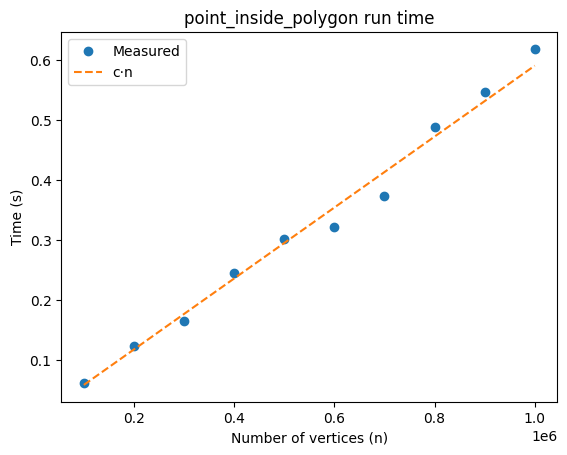

In [4]:
import time
import statistics
import matplotlib.pyplot as plt

sizes = list(range(100_000, 1_000_001, 100_000))
times = []

for n in sizes:
    poly = regular_polygon(n)
    runs = []
    for _ in range(5):
        start = time.perf_counter()
        point_inside_polygon(poly, (0, 0))
        runs.append(time.perf_counter() - start)
    times.append(statistics.median(runs))

results = pd.DataFrame({"n": sizes, "Time (s)": times})
results["Time / n (ns)"] = results["Time (s)"] / results["n"] * 1e9
display(results.round(4))

slope = sum(t / n for n, t in zip(sizes, times)) / len(sizes)
plt.plot(sizes, times, "o", label="Measured")
plt.plot(sizes, [slope * n for n in sizes], "--", label="c·n")
plt.xlabel("Number of vertices (n)")
plt.ylabel("Time (s)")
plt.title("point_inside_polygon run time")
plt.legend()
plt.show()

### Benchmark Results

The measured times fall on a straight line through the origin, and doubling n roughly doubles the run time (0.062 s at n = 100,000 vs. 0.123 s at n = 200,000). The time per vertex stays between about 530 and 620 ns across all sizes instead of growing with n. Both observations match the theoretical Θ(n) run time, where the constant c is the cost of one call to `ray_crossing` plus loop overhead.

*Completed by @BrettStoroe*

### Team Member Contributions

#### Kaiden Pollesch
- Decision Rule and Illustrations
- High-Level Pseudocode
- Correctness Justification

#### Braden Everson
- Algorithm Implementation
- Runtime Analysis

#### Brett Storoe
- Test Cases
- Benchmarking
- Benchmarking Results